In [1]:
import pandas as pd
import pyarrow.parquet as pq

PARQUET_FILE = "input/data/solver_results.parquet"

# Just metadata - very fast, no data load
pf = pq.ParquetFile(PARQUET_FILE)
print(pf.schema)              # schema with types
print(pf.metadata)            # row count, row groups, size
print(pf.metadata.num_rows)

# Read only specific columns
# df = pq.read_table(PARQUET_FILE, columns=['col1', 'col2']).to_pandas()

required group field_id=-1 schema {
  optional binary field_id=-1 id (String);
  optional binary field_id=-1 prompt (String);
  optional binary field_id=-1 answer (String);
  optional binary field_id=-1 solver_answer (String);
  optional boolean field_id=-1 solver_correct;
  optional binary field_id=-1 solver_type (String);
  optional binary field_id=-1 solver_category (String);
  optional boolean field_id=-1 conditioned_on_answer;
  optional binary field_id=-1 solver_mode (String);
  optional binary field_id=-1 solver_ops (String);
  optional binary field_id=-1 solver_mapping (String);
  optional double field_id=-1 solver_tier;
  optional binary field_id=-1 solver_level (String);
  optional double field_id=-1 solver_radix;
  optional double field_id=-1 solver_numeric_answer;
  optional binary field_id=-1 op_counts (String);
  optional int64 field_id=-1 min_op_count;
  optional int64 field_id=-1 num_ops;
}

  created_by: parquet-cpp-arrow version 24.0.0
  num_columns: 18
  num_rows: 82

In [2]:
df = pq.read_table(PARQUET_FILE, columns=['id', 'prompt', 'answer']).to_pandas()
df

,id,prompt,answer
0,00457d26,"In Alice's Wonderland, a secret set of transfo...",@&
1,00c032a8,"In Alice's Wonderland, a secret set of transfo...",\^?
2,012cab1f,"In Alice's Wonderland, a secret set of transfo...",|@{
3,0133bcec,"In Alice's Wonderland, a secret set of transfo...",\([#
4,017a871e,"In Alice's Wonderland, a secret set of transfo...",\:
...,...,...,...
818,fdbdf50c,"In Alice's Wonderland, a secret set of transfo...","-\"""
819,fe6da79d,"In Alice's Wonderland, a secret set of transfo...",:&]!
820,ff0e37ae,"In Alice's Wonderland, a secret set of transfo...","%'""`"
821,ff121f08,"In Alice's Wonderland, a secret set of transfo...",#<


In [3]:
import pyarrow.parquet as pq
import json

PARQUET_FILE = "input/data/solver_results.parquet"
OUTPUT_FILE = 'input/data/symbolic_equation_samples.jsonl'

# Read only the columns you need
df = pq.read_table(PARQUET_FILE, columns=['id', 'prompt', 'answer']).to_pandas()

# Write JSONL
with open(OUTPUT_FILE, 'w', encoding='utf-8') as f:
    for _, row in df.iterrows():
        record = {
            "dataset": "SymbolicEquationSamples",
            "source": "training_free_grpo",
            "question": row['prompt'],
            "answer": row['answer'] if row['answer'] is not None else None
        }
        f.write(json.dumps(record, ensure_ascii=False) + '\n')

print(f"Wrote {len(df)} records to {OUTPUT_FILE}")

Wrote 823 records to input/data/symbolic_equation_samples.jsonl


In [4]:
df['prompt'][0]

'In Alice\'s Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:\n`!*[{ = \'"[`\n\\\'*\'> = ![@\n\\\'-!` = \\\\\n`!*\\& = \'@\'{\nNow, determine the result for: [[-!\''

In [5]:
import re

all_symbols = set()

for text in df["prompt"].dropna():
    examples_match = re.search(
        r'Below are a few examples:\n(.*?)\nNow, determine the result for:',
        text, re.DOTALL
    )
    query_match = re.search(
        r'\nNow, determine the result for: (.*)',
        text
    )
    for match in [examples_match, query_match]:
        if match:
            all_symbols.update(re.findall(r'[^a-zA-Z0-9\s]', match.group(1)))

for text in df["answer"].dropna():
    all_symbols.update(re.findall(r'[^a-zA-Z0-9\s]', text))

print(sorted(all_symbols))
print(f"Total unique symbols: {len(all_symbols)}")

['!', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', '-', '/', ':', '<', '=', '>', '?', '@', '[', '\\', ']', '^', '`', '{', '|', '}']
Total unique symbols: 27


In [6]:
import string

# 27 symbols found; '=' keeps itself, the other 26 map to A-Z
symbols_no_eq = [s for s in sorted(all_symbols) if s != '=']
symbol_to_letter = {s: letter for s, letter in zip(symbols_no_eq, string.ascii_uppercase)}
symbol_to_letter['='] = '='

print(symbol_to_letter)


def map_section(text, mapping):
    return ''.join(mapping.get(ch, ch) for ch in text)

def map_prompt_symbols(text, mapping):
    examples_match = re.search(
        r'(Below are a few examples:\n)(.*?)(\nNow, determine the result for: )(.*)',
        text, re.DOTALL
    )
    if not examples_match:
        return text
    prefix    = text[:examples_match.start(2)]
    examples  = map_section(examples_match.group(2), mapping)
    separator = examples_match.group(3)
    query     = map_section(examples_match.group(4), mapping)
    return prefix + examples + separator + query


df['mapped_prompt'] = df['prompt'].apply(lambda t: map_prompt_symbols(t, symbol_to_letter))
df['mapped_answer'] = df['answer'].apply(lambda t: map_section(t, symbol_to_letter) if pd.notna(t) else t)
df[['prompt', 'mapped_prompt', 'answer', 'mapped_answer']].head(3)


{'!': 'A', '"': 'B', '#': 'C', '$': 'D', '%': 'E', '&': 'F', "'": 'G', '(': 'H', ')': 'I', '*': 'J', '+': 'K', '-': 'L', '/': 'M', ':': 'N', '<': 'O', '>': 'P', '?': 'Q', '@': 'R', '[': 'S', '\\': 'T', ']': 'U', '^': 'V', '`': 'W', '{': 'X', '|': 'Y', '}': 'Z', '=': '='}


,prompt,mapped_prompt,answer,mapped_answer
0,"In Alice's Wonderland, a secret set of transfo...","In Alice's Wonderland, a secret set of transfo...",@&,RF
1,"In Alice's Wonderland, a secret set of transfo...","In Alice's Wonderland, a secret set of transfo...",\^?,TVQ
2,"In Alice's Wonderland, a secret set of transfo...","In Alice's Wonderland, a secret set of transfo...",|@{,YRX


In [7]:
import pyarrow.parquet as pq
import json

PARQUET_FILE = "input/data/solver_results.parquet"
OUTPUT_FILE = 'input/data/mapped_symbolic_equation_samples.jsonl'

# Write JSONL
with open(OUTPUT_FILE, 'w', encoding='utf-8') as f:
    for _, row in df.iterrows():
        record = {
            "dataset": "SymbolicEquationSamples",
            "source": "training_free_grpo",
            "question": row['mapped_prompt'],
            "answer": row['mapped_answer'] if row['mapped_answer'] is not None else None
        }
        f.write(json.dumps(record, ensure_ascii=False) + '\n')

print(f"Wrote {len(df)} records to {OUTPUT_FILE}")

Wrote 823 records to input/data/mapped_symbolic_equation_samples.jsonl


# Data Analysis

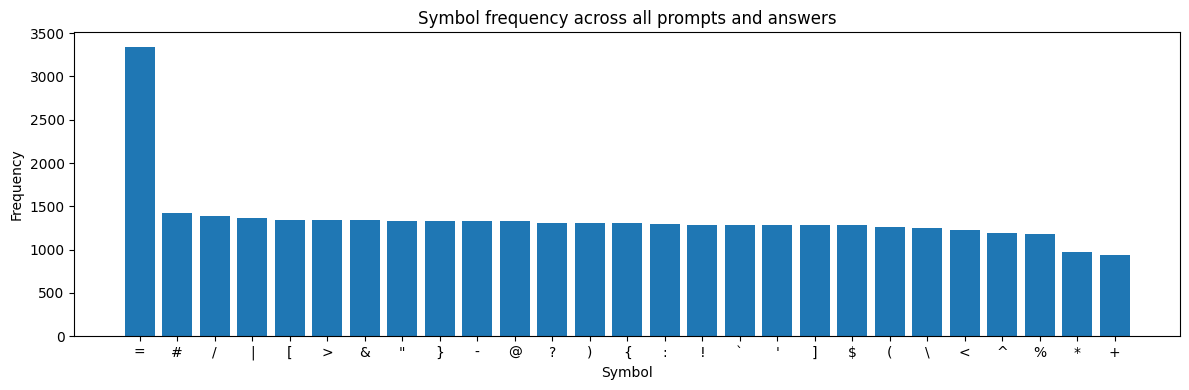

In [8]:
from collections import Counter
import matplotlib.pyplot as plt

char_counts = Counter()

for text in df["prompt"].dropna():
    examples_match = re.search(
        r'Below are a few examples:\n(.*?)\nNow, determine the result for:',
        text, re.DOTALL
    )
    query_match = re.search(r'\nNow, determine the result for: (.*)', text)
    for match in [examples_match, query_match]:
        if match:
            char_counts.update(re.findall(r'[^a-zA-Z0-9\s]', match.group(1)))

for text in df["answer"].dropna():
    char_counts.update(re.findall(r'[^a-zA-Z0-9\s]', text))

chars, freqs = zip(*sorted(char_counts.items(), key=lambda x: -x[1]))

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(chars, freqs)
ax.set_xlabel("Symbol")
ax.set_ylabel("Frequency")
ax.set_title("Symbol frequency across all prompts and answers")
plt.tight_layout()
plt.show()


In [ ]:
print(f"{'Symbol':<8} {'Letter':<8} {'Frequency'}")
print("-" * 28)
for char, freq in sorted(char_counts.items(), key=lambda x: -x[1]):
    if char == '=':
        continue
    letter = symbol_to_letter.get(char, char)
    print(f"{char!r:<8} {letter:<8} {freq}")


In [17]:
print(f"={'Letter':<8} {'Frequency'}")
print("-" * 28)
for char, freq in sorted(char_counts.items(), key=lambda x: -x[1]):
    if char == '=':
        continue
    letter = symbol_to_letter.get(char, char)
    print(f"{letter:<8} {freq}")


=Letter   Frequency
----------------------------
C        1424
M        1391
Y        1363
S        1340
P        1340
F        1339
B        1332
Z        1330
L        1326
R        1325
Q        1308
I        1305
X        1302
N        1294
A        1290
W        1288
G        1284
U        1282
D        1279
H        1259
T        1253
O        1224
V        1194
E        1182
J        967
K        941


## 1. Are all LHS of length 5?

In [8]:
from collections import Counter

lhs_lengths = []

for text in df["prompt"].dropna():
    examples_match = re.search(
        r'Below are a few examples:\n(.*?)\nNow, determine the result for:',
        text, re.DOTALL
    )
    if examples_match:
        for rule in examples_match.group(1).strip().split('\n'):
            if ' = ' in rule:
                lhs = rule.split(' = ', 1)[0]
                lhs_lengths.append(len(lhs))

length_counts = Counter(lhs_lengths)
print(f"LHS length distribution: {dict(sorted(length_counts.items()))}")
print(f"All LHS length 5: {all(l == 5 for l in lhs_lengths)}")


LHS length distribution: {5: 3342}
All LHS length 5: True


## 2. Frequency of RHS lengths (rules + answers)

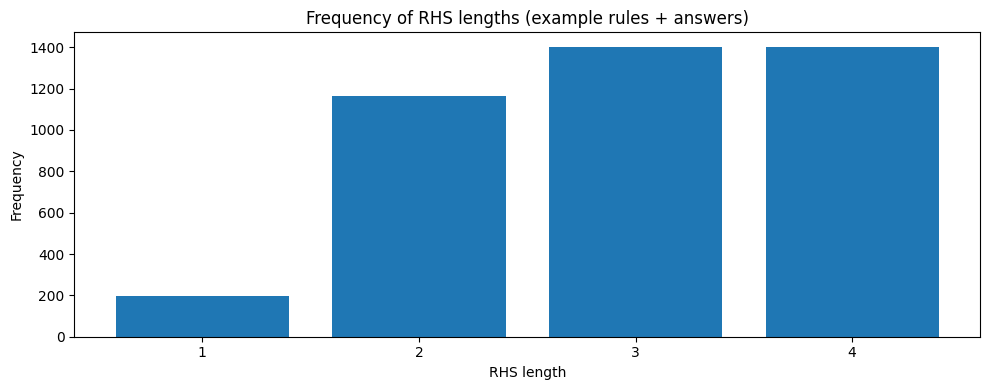

RHS length distribution: {1: 199, 2: 1162, 3: 1402, 4: 1402}


In [9]:
rhs_lengths = []

for text in df["prompt"].dropna():
    examples_match = re.search(
        r'Below are a few examples:\n(.*?)\nNow, determine the result for:',
        text, re.DOTALL
    )
    if examples_match:
        for rule in examples_match.group(1).strip().split('\n'):
            if ' = ' in rule:
                rhs = rule.split(' = ', 1)[1]
                rhs_lengths.append(len(rhs))

for text in df["answer"].dropna():
    rhs_lengths.append(len(text))

length_counts = Counter(rhs_lengths)
lengths = sorted(length_counts.keys())
freqs = [length_counts[l] for l in lengths]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lengths, freqs)
ax.set_xticks(lengths)
ax.set_xlabel("RHS length")
ax.set_ylabel("Frequency")
ax.set_title("Frequency of RHS lengths (example rules + answers)")
plt.tight_layout()
plt.show()

print(f"RHS length distribution: {dict(zip(lengths, freqs))}")


### Inspect short RHS cases (length 1, 2, 3)

In [12]:
# Collect all (lhs, rhs, source) triples with their lengths
rhs_records = []

for text in df["prompt"].dropna():
    examples_match = re.search(
        r'Below are a few examples:\n(.*?)\nNow, determine the result for:',
        text, re.DOTALL
    )
    if examples_match:
        for rule in examples_match.group(1).strip().split('\n'):
            if ' = ' in rule:
                lhs, rhs = rule.split(' = ', 1)
                rhs_records.append({"lhs": lhs, "rhs": rhs, "rhs_len": len(rhs), "source": "rule"})

for text in df["answer"].dropna():
    rhs_records.append({"lhs": None, "rhs": text, "rhs_len": len(text), "source": "answer"})

df_rhs = pd.DataFrame(rhs_records)
df_rhs.head()


,lhs,rhs,rhs_len,source
0,`!*[{,"'""[`",4,rule
1,\'*'>,![@,3,rule
2,\'-!`,\\,2,rule
3,`!*\&,'@'{,4,rule
4,}`]?(,()),3,rule


In [13]:
for length in [1, 2, 3]:
    subset = df_rhs[df_rhs["rhs_len"] == length]
    print(f"\n--- RHS length {length} ({len(subset)} cases) ---")
    print(subset[["lhs", "rhs", "source"]].to_string(index=False))



--- RHS length 1 (199 cases) ---
  lhs rhs source
"%-!@   "   rule
/}-\`   ]   rule
'@<(&   #   rule
[!-)!   )   rule
&!-][   `   rule
]"-"%   @   rule
)(-)(   "   rule
&(-((   <   rule
:$-:[   }   rule
$?"|/   $   rule
]!"?/   #   rule
<|^<"   &   rule
@"!")   ?   rule
<}-}}   $   rule
{[*(#   >   rule
{>-^>   '   rule
{>-[{   }   rule
\\-\"   ]   rule
""-[#   '   rule
'|-{[   #   rule
(:-]:   @   rule
]{-]{   :   rule
?[-?>   %   rule
|&"^>   ^   rule
&}-&&   "   rule
$|-$%   $   rule
}%-$`   }   rule
]@)@|   @   rule
#?+#|   ^   rule
(?-('   '   rule
@!->:   `   rule
">-"?   ?   rule
}(-|<   :   rule
&#^&)   {   rule
`(}/(   `   rule
>[-[`   /   rule
/:*:]   ]   rule
@]*]|   )   rule
{&->:   {   rule
&/@&[   &   rule
|{-(!   (   rule
}{-%(   }   rule
!>-!|   !   rule
$<-/<   <   rule
#!-^%   !   rule
>?-}?   >   rule
""-[:   ?   rule
]/-]:   `   rule
/)&#@   }   rule
!(-?(   `   rule
<\-<\   \   rule
!]-$|   '   rule
}!)#}   ]   rule
!&-"$   <   rule
{!-"&   /   rule
}(-}(   ^   ru

## 3. Answers containing symbols absent from their examples

In [10]:
rows_with_new_symbols = 0
total_new_symbol_occurrences = 0
examples_list = []

for _, row in df.iterrows():
    text, answer = row['prompt'], row['answer']
    if pd.isna(text) or pd.isna(answer):
        continue

    examples_match = re.search(
        r'Below are a few examples:\n(.*?)\nNow, determine the result for:',
        text, re.DOTALL
    )
    if not examples_match:
        continue

    symbols_in_examples = set(re.findall(r'[^a-zA-Z0-9\s=]', examples_match.group(1)))
    answer_symbols = re.findall(r'[^a-zA-Z0-9\s=]', answer)
    new_in_answer = [s for s in answer_symbols if s not in symbols_in_examples]

    if new_in_answer:
        rows_with_new_symbols += 1
        total_new_symbol_occurrences += len(new_in_answer)
        examples_list.append({"answer": answer, "new_symbols": new_in_answer, "example_symbols": symbols_in_examples})

total = len(df.dropna(subset=['prompt', 'answer']))
print(f"Rows where answer has a symbol absent from examples: {rows_with_new_symbols} / {total} ({rows_with_new_symbols/total*100:.1f}%)")
print(f"Total such symbol occurrences: {total_new_symbol_occurrences}")
print("\nSample cases:")
for case in examples_list[:5]:
    print(f"  answer={case['answer']!r}  new={case['new_symbols']}  example_symbols={sorted(case['example_symbols'])}")


Rows where answer has a symbol absent from examples: 196 / 823 (23.8%)
Total such symbol occurrences: 231

Sample cases:
  answer='\\^?'  new=['^']  example_symbols=['!', '#', '&', '(', ')', '<', '?', '@', '\\', ']', '`', '}']
  answer='|@{'  new=['|']  example_symbols=['"', '#', '%', '&', "'", '(', ':', '>', '@', ']', '`', '{']
  answer='\\([#'  new=['#']  example_symbols=['"', '%', '(', '*', '+', '-', '@', '[', '\\', '^', '|']
  answer='(@(]'  new=['(', '(']  example_symbols=['"', '#', '$', '%', '&', '*', '+', '-', '?', '@', '\\', ']']
  answer='<#):'  new=['#']  example_symbols=['!', '"', '&', '(', ')', '*', '-', '/', ':', '<', '[']


## 4. Unique symbols per sample

In [10]:
from collections import Counter

unique_per_sample = []

for _, row in df.iterrows():
    text, answer = row["prompt"], row["answer"]
    if pd.isna(text):
        continue
    examples_match = re.search(
        r'Below are a few examples:\n(.*?)\nNow, determine the result for:',
        text, re.DOTALL
    )
    query_match = re.search(r'\nNow, determine the result for: (.*)', text)
    syms = set()
    for match in [examples_match, query_match]:
        if match:
            syms.update(re.findall(r'[^a-zA-Z0-9\s=]', match.group(1)))
    if pd.notna(answer):
        syms.update(re.findall(r'[^a-zA-Z0-9\s=]', answer))
    unique_per_sample.append(len(syms))

counts = Counter(unique_per_sample)
print(f"{'Unique symbols':<18} {'# samples'}")
print("-" * 30)
for k in sorted(counts):
    print(f"{k:<18} {counts[k]}")

print(f"\nMin: {min(unique_per_sample)}, Max: {max(unique_per_sample)}, Mean: {sum(unique_per_sample)/len(unique_per_sample):.2f}")

Unique symbols     # samples
------------------------------
8                  1
9                  2
10                 33
11                 132
12                 317
13                 338

Min: 8, Max: 13, Mean: 12.16


In [13]:
df['prompt'][0]

'In Alice\'s Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:\n`!*[{ = \'"[`\n\\\'*\'> = ![@\n\\\'-!` = \\\\\n`!*\\& = \'@\'{\nNow, determine the result for: [[-!\''

In [14]:
df['mapped_prompt'][0]

"In Alice's Wonderland, a secret set of transformation rules is applied to equations. Below are a few examples:\nWAJSX = GBSW\nTGJGP = ASR\nTGLAW = TT\nWAJTF = GRGX\nNow, determine the result for: SSLAG"

Wrote 823 records to input/symbolic_equation_samples.jsonl
